---
title: "Plotting with PyMC and Arviz"
author: "Sheng Long"
date: "12/18/25"
draft: true 
---

:::{.callout-note}
# TLDR 

This post is about trying to answer a simple question: to what extent does existing functionalities of `pymc` and `arviz` implement what can be done in `tidybayes` ...? 

Trying to implement the examples [here](https://mjskay.github.io/tidybayes/articles/tidy-brms.html). 

:::


In [20]:
import arviz as az 
import pandas as pd 
import pymc as pm 
import numpy as np 
import matplotlib.pyplot as plt
az.style.use("arviz-docgrid")

In [23]:
RANDOM_SEED = 5
rng = np.random.default_rng(RANDOM_SEED)
n = 10
n_condition = 5
ABC = pd.DataFrame(rng.normal([0, 1, 2, 1, -1], scale=0.5, size=(n, n_condition))).set_axis(['A', 'B', 'C', 'D', 'E'], axis='columns')
ABC = pd.melt(ABC)

A snapshot of the data looks like this: 

In [24]:
ABC.head(10)

,variable,value
0,A,-0.400966
1,A,0.054853
2,A,0.136384
3,A,-0.866067
4,A,-0.356657
5,A,0.414928
6,A,-0.644709
7,A,-0.198095
8,A,0.585148
9,A,0.016529


We can try to plot is as follows: 

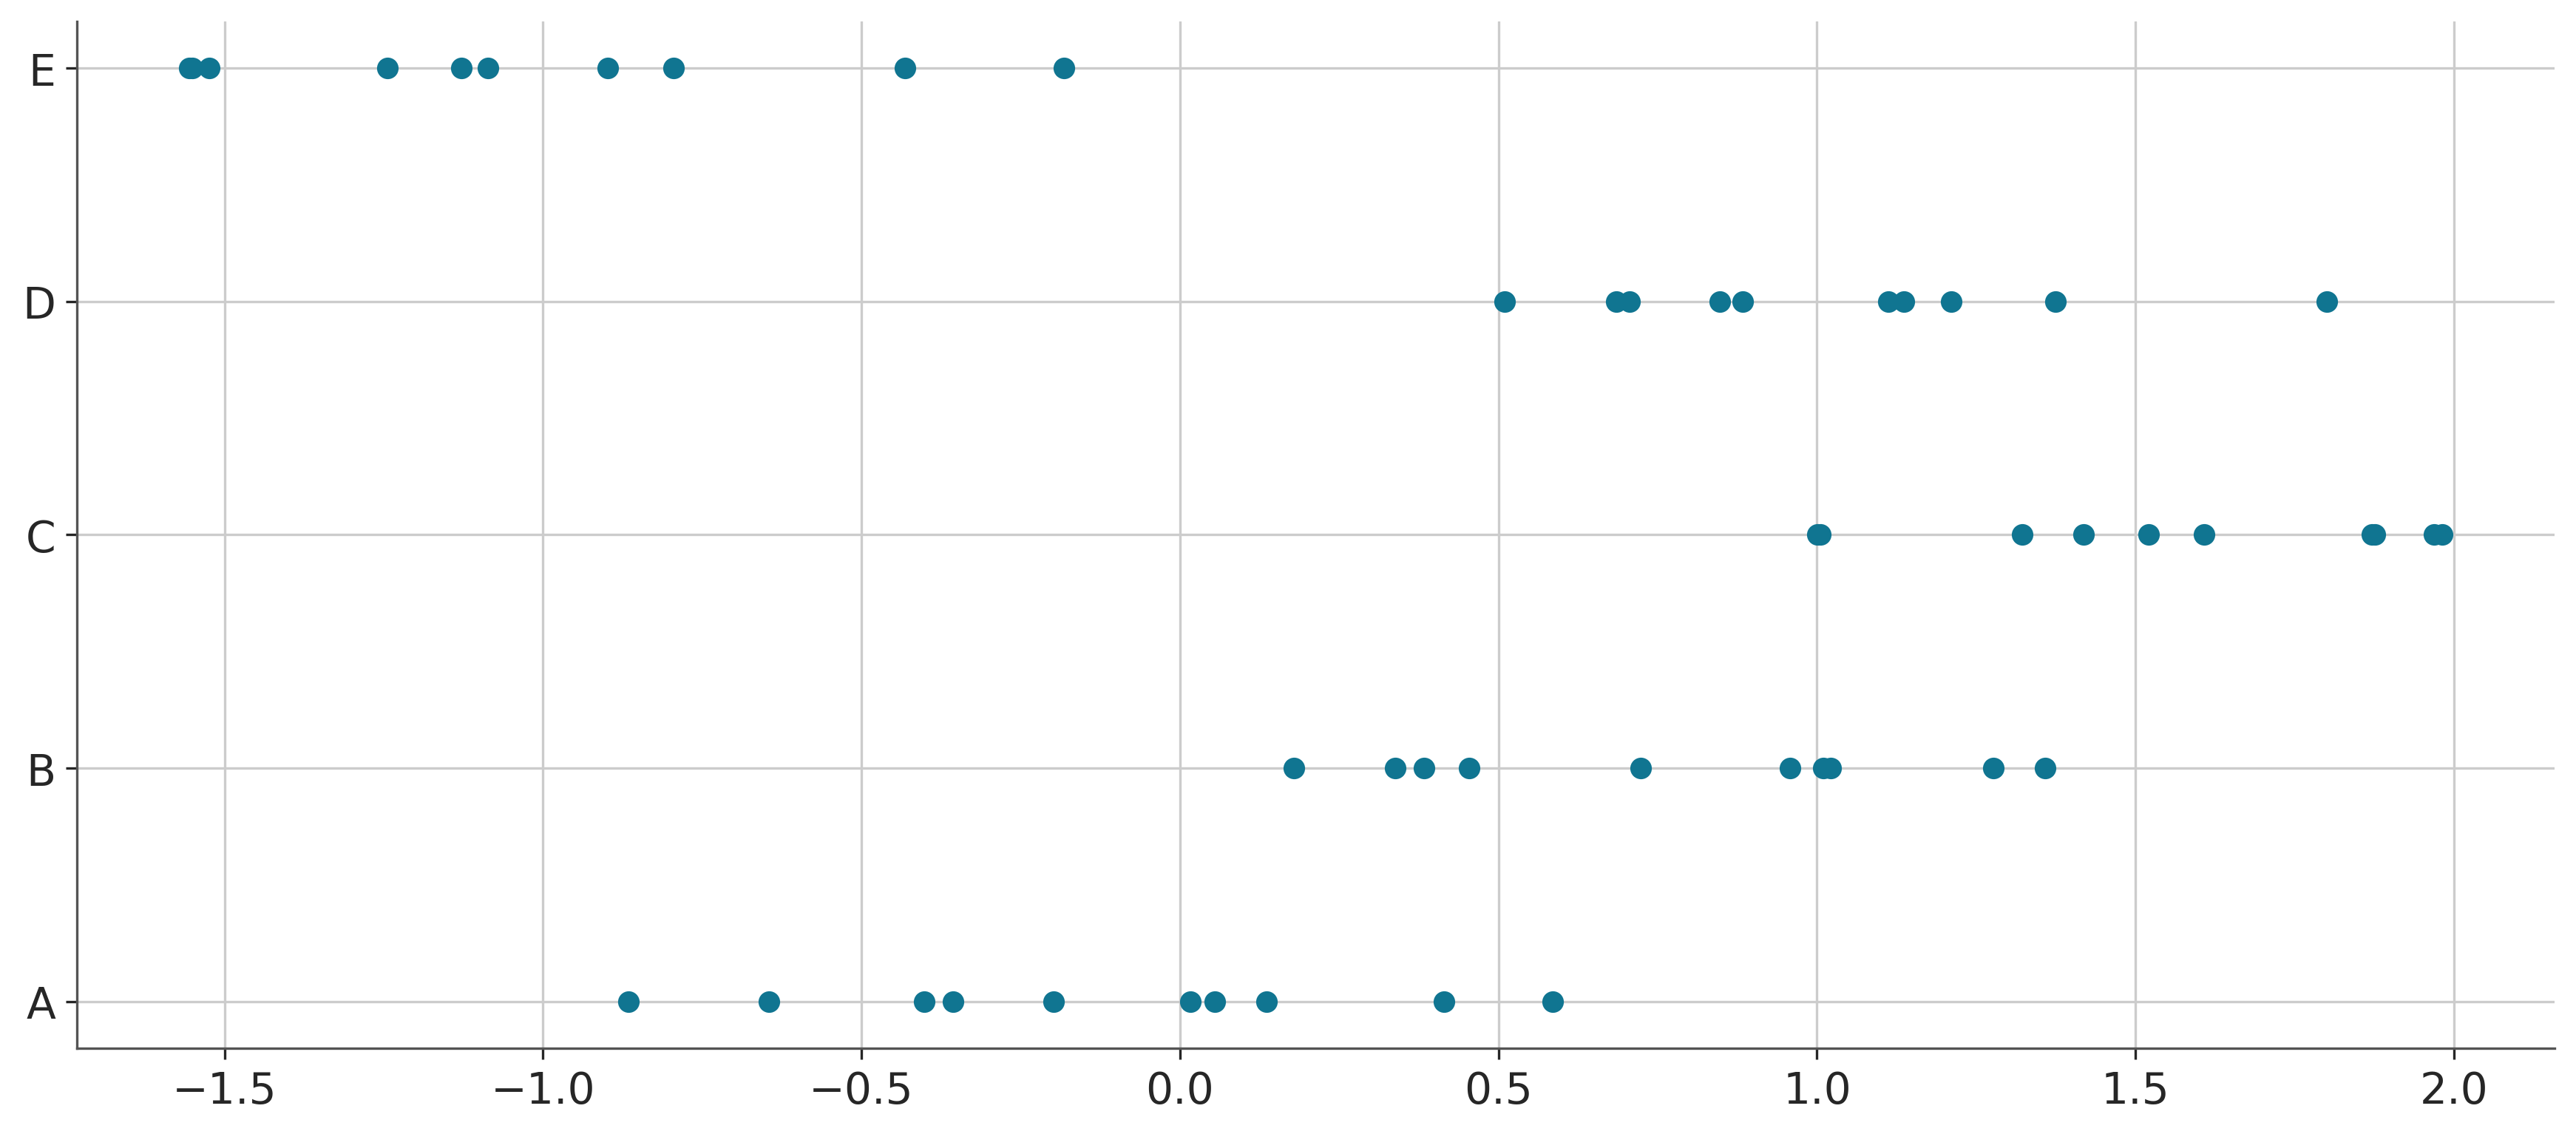

In [25]:
fig, ax = plt.subplots()
ax.scatter(data=ABC, x = "value", y = "variable")

## Model

We can fit a hierarchical model with shrinkage towards a global mean. The mathematical formulation is as follows: 

$$
\begin{align}
\texttt{value} &\sim \mathcal{N}(\alpha_{\text{variable}[i]}, \sigma) \\
\alpha_j &\sim \mathcal{N}(\bar{\alpha}, \sigma_\alpha), j \in [5] \\ 
\bar{\alpha} &\sim \mathcal{N}(0, 1) \\ 
\sigma_\alpha &\sim \text{student-t}^+(3, 0, 1) \\  
\sigma &\sim \text{student-t}^+(3, 0, 1) \\ 
\end{align}
$$

In [32]:
var_idx, var_value = pd.factorize(ABC['variable'])
coords = {
    'var': var_value
}

In [55]:
with pm.Model(coords=coords) as ABC_model:
    # priors and hyperpriors 
    alpha_bar = pm.Normal("alpha_bar", 0, 1)
    sigma_alpha = pm.HalfStudentT("sigma_alpha", nu=3, sigma=1)
    sigma = pm.HalfStudentT("sigma", nu=3, sigma=1)
    # likelihood ...? 
    alpha = pm.Normal("alpha", alpha_bar, sigma_alpha, dims="var")
    y_obs = pm.Normal("y_obs", mu=alpha[var_idx],sigma=sigma,observed=ABC['value'])


In [56]:
with ABC_model:
    idata = pm.sample(progressbar=False)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha_bar, sigma_alpha, sigma, alpha]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 14 seconds.


In [57]:
idata

[autoreload of cutils_ext failed: Traceback (most recent call last):
  File "/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 580, in superreload
    module = reload(module)
  File "/Users/shenglong/.local/share/uv/python/cpython-3.13.9-macos-x86_64-none/lib/python3.13/importlib/__init__.py", line 128, in reload
    raise ModuleNotFoundError(f"spec not found for the module {name!r}", name=name)
ModuleNotFoundError: spec not found for the module 'cutils_ext'
]


Inference data with groups:
	> posterior
	> sample_stats
	> observed_data

In [ ]:
#| code-fold: true 

# save fitted posterior 
# idata.to_netcdf("ABC_posterior.nc")

'ABC_posterior.nc'

In [44]:
az.summary(idata)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha_bar,0.346,0.478,-0.592,1.228,0.008,0.010,4015.0,2449.0,1.0
alpha[A],-0.115,0.135,-0.360,0.140,0.002,0.002,5378.0,3192.0,1.0
alpha[B],0.763,0.135,0.503,1.006,0.002,0.003,4364.0,2812.0,1.0
alpha[C],1.535,0.136,1.287,1.789,0.002,0.002,4715.0,3417.0,1.0
alpha[D],1.015,0.139,0.752,1.268,0.002,0.002,4456.0,2437.0,1.0
alpha[E],-1.010,0.139,-1.255,-0.745,0.002,0.002,5564.0,2961.0,1.0
sigma_alpha,1.137,0.419,0.548,1.881,0.008,0.011,3252.0,2802.0,1.0
sigma,0.431,0.048,0.346,0.526,0.001,0.001,3680.0,2847.0,1.0


In [46]:
idata.posterior

<xarray.Dataset> Size: 264kB
Dimensions:      (chain: 4, draw: 1000, var: 5)
Coordinates:
  * chain        (chain) int64 32B 0 1 2 3
  * draw         (draw) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * var          (var) <U1 20B 'A' 'B' 'C' 'D' 'E'
Data variables:
    alpha_bar    (chain, draw) float64 32kB 0.555 -0.2105 0.956 ... 0.6464 1.367
    alpha        (chain, draw, var) float64 160kB -0.02397 0.7852 ... -1.083
    sigma_alpha  (chain, draw) float64 32kB 1.01 0.8667 0.99 ... 1.338 1.242
    sigma        (chain, draw) float64 32kB 0.4027 0.4379 ... 0.4077 0.3867
Attributes:
    created_at:                 2025-12-18T15:30:30.411124+00:00
    arviz_version:              0.22.0
    inference_library:          pymc
    inference_library_version:  5.26.1
    sampling_time:              15.825407981872559
    tuning_steps:               1000

array([<Axes: title={'center': '95.0% HDI'}>], dtype=object)

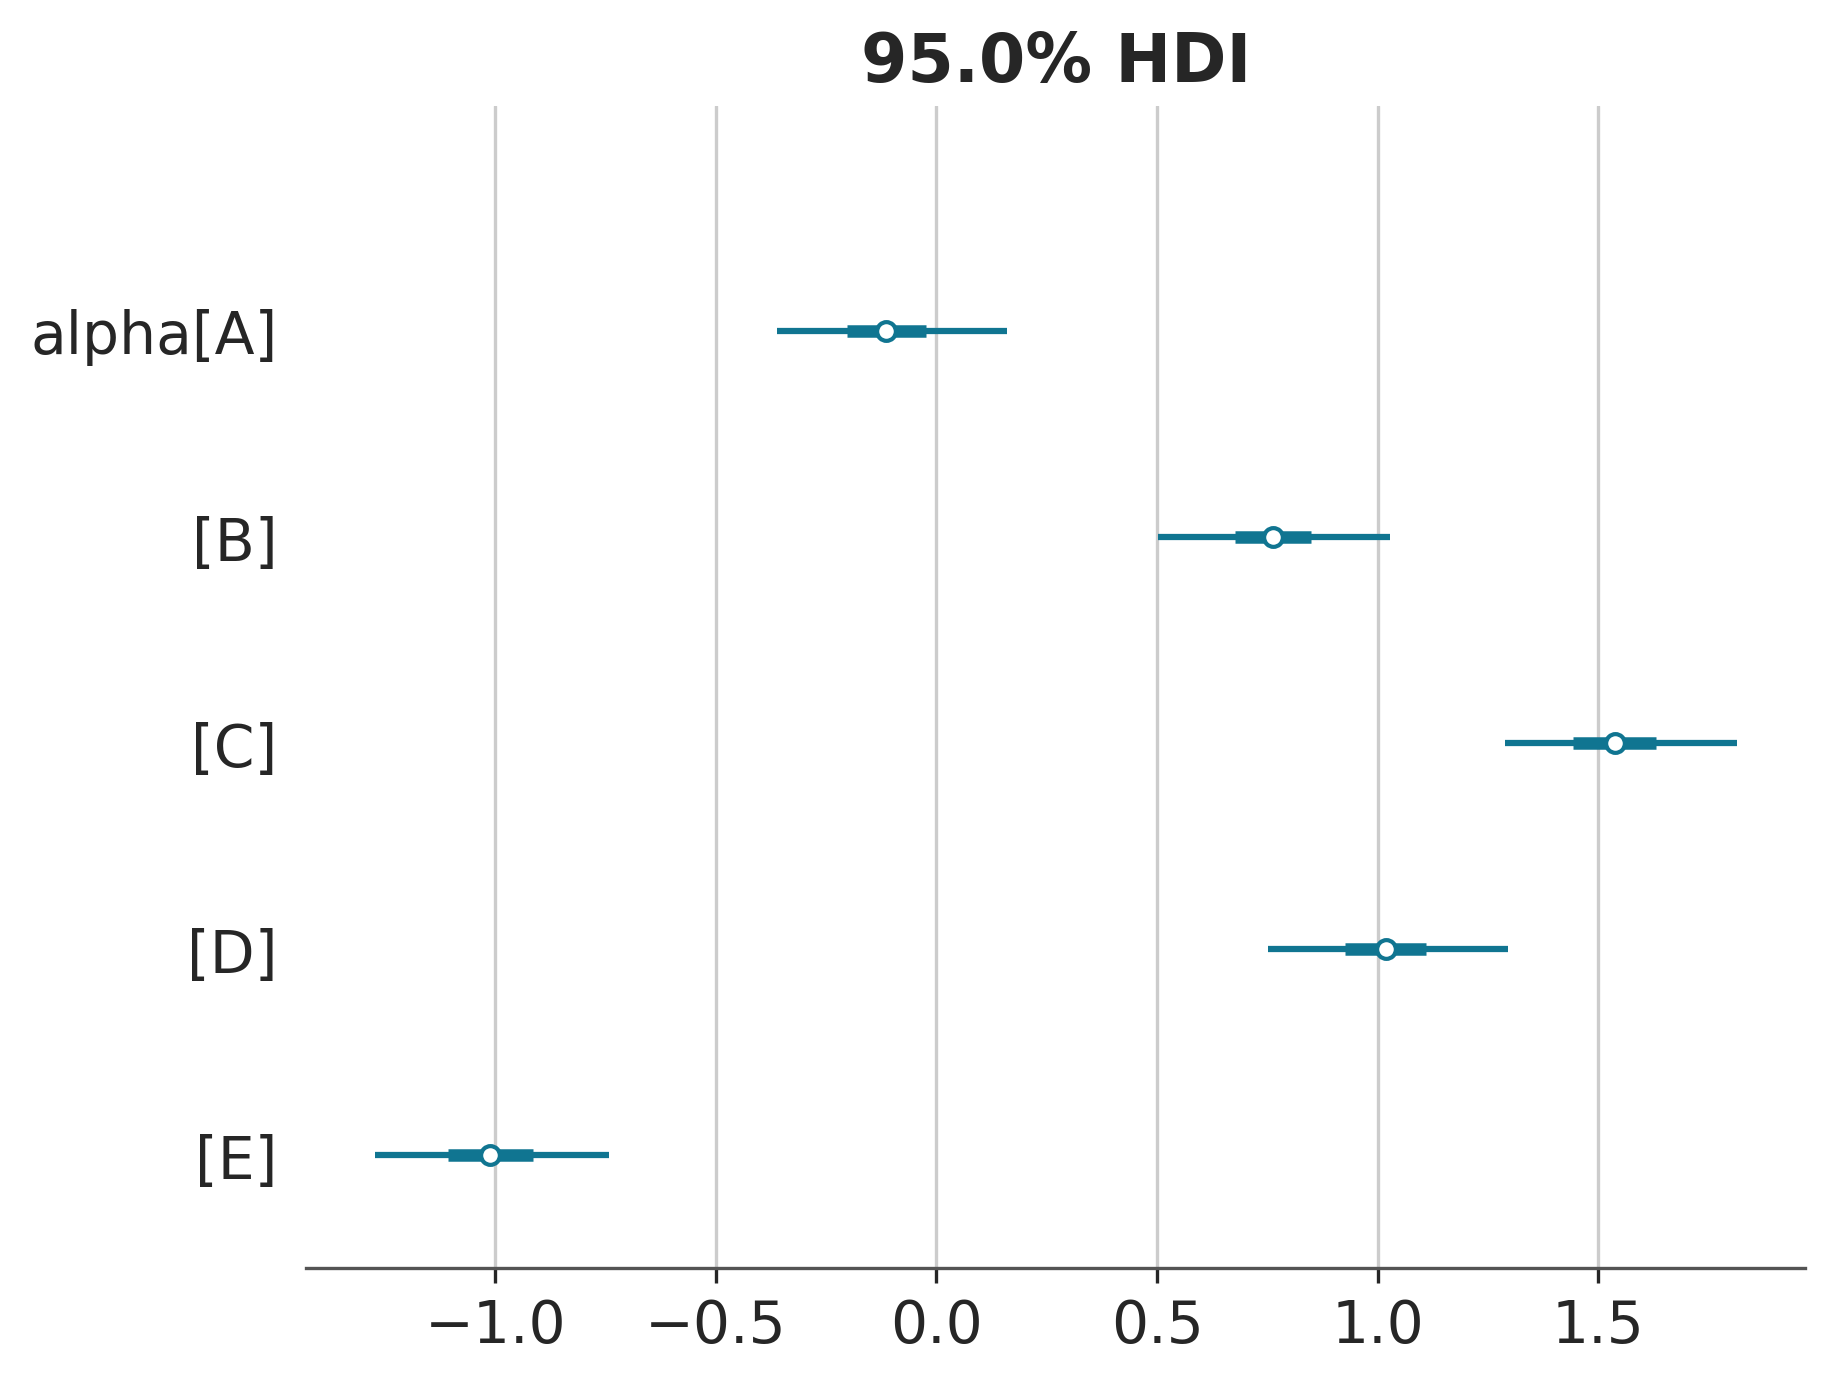

In [51]:
az.plot_forest(idata, combined=True, var_names=["alpha"], hdi_prob=0.95)

## Intervals with densities 

array([<Axes: >], dtype=object)

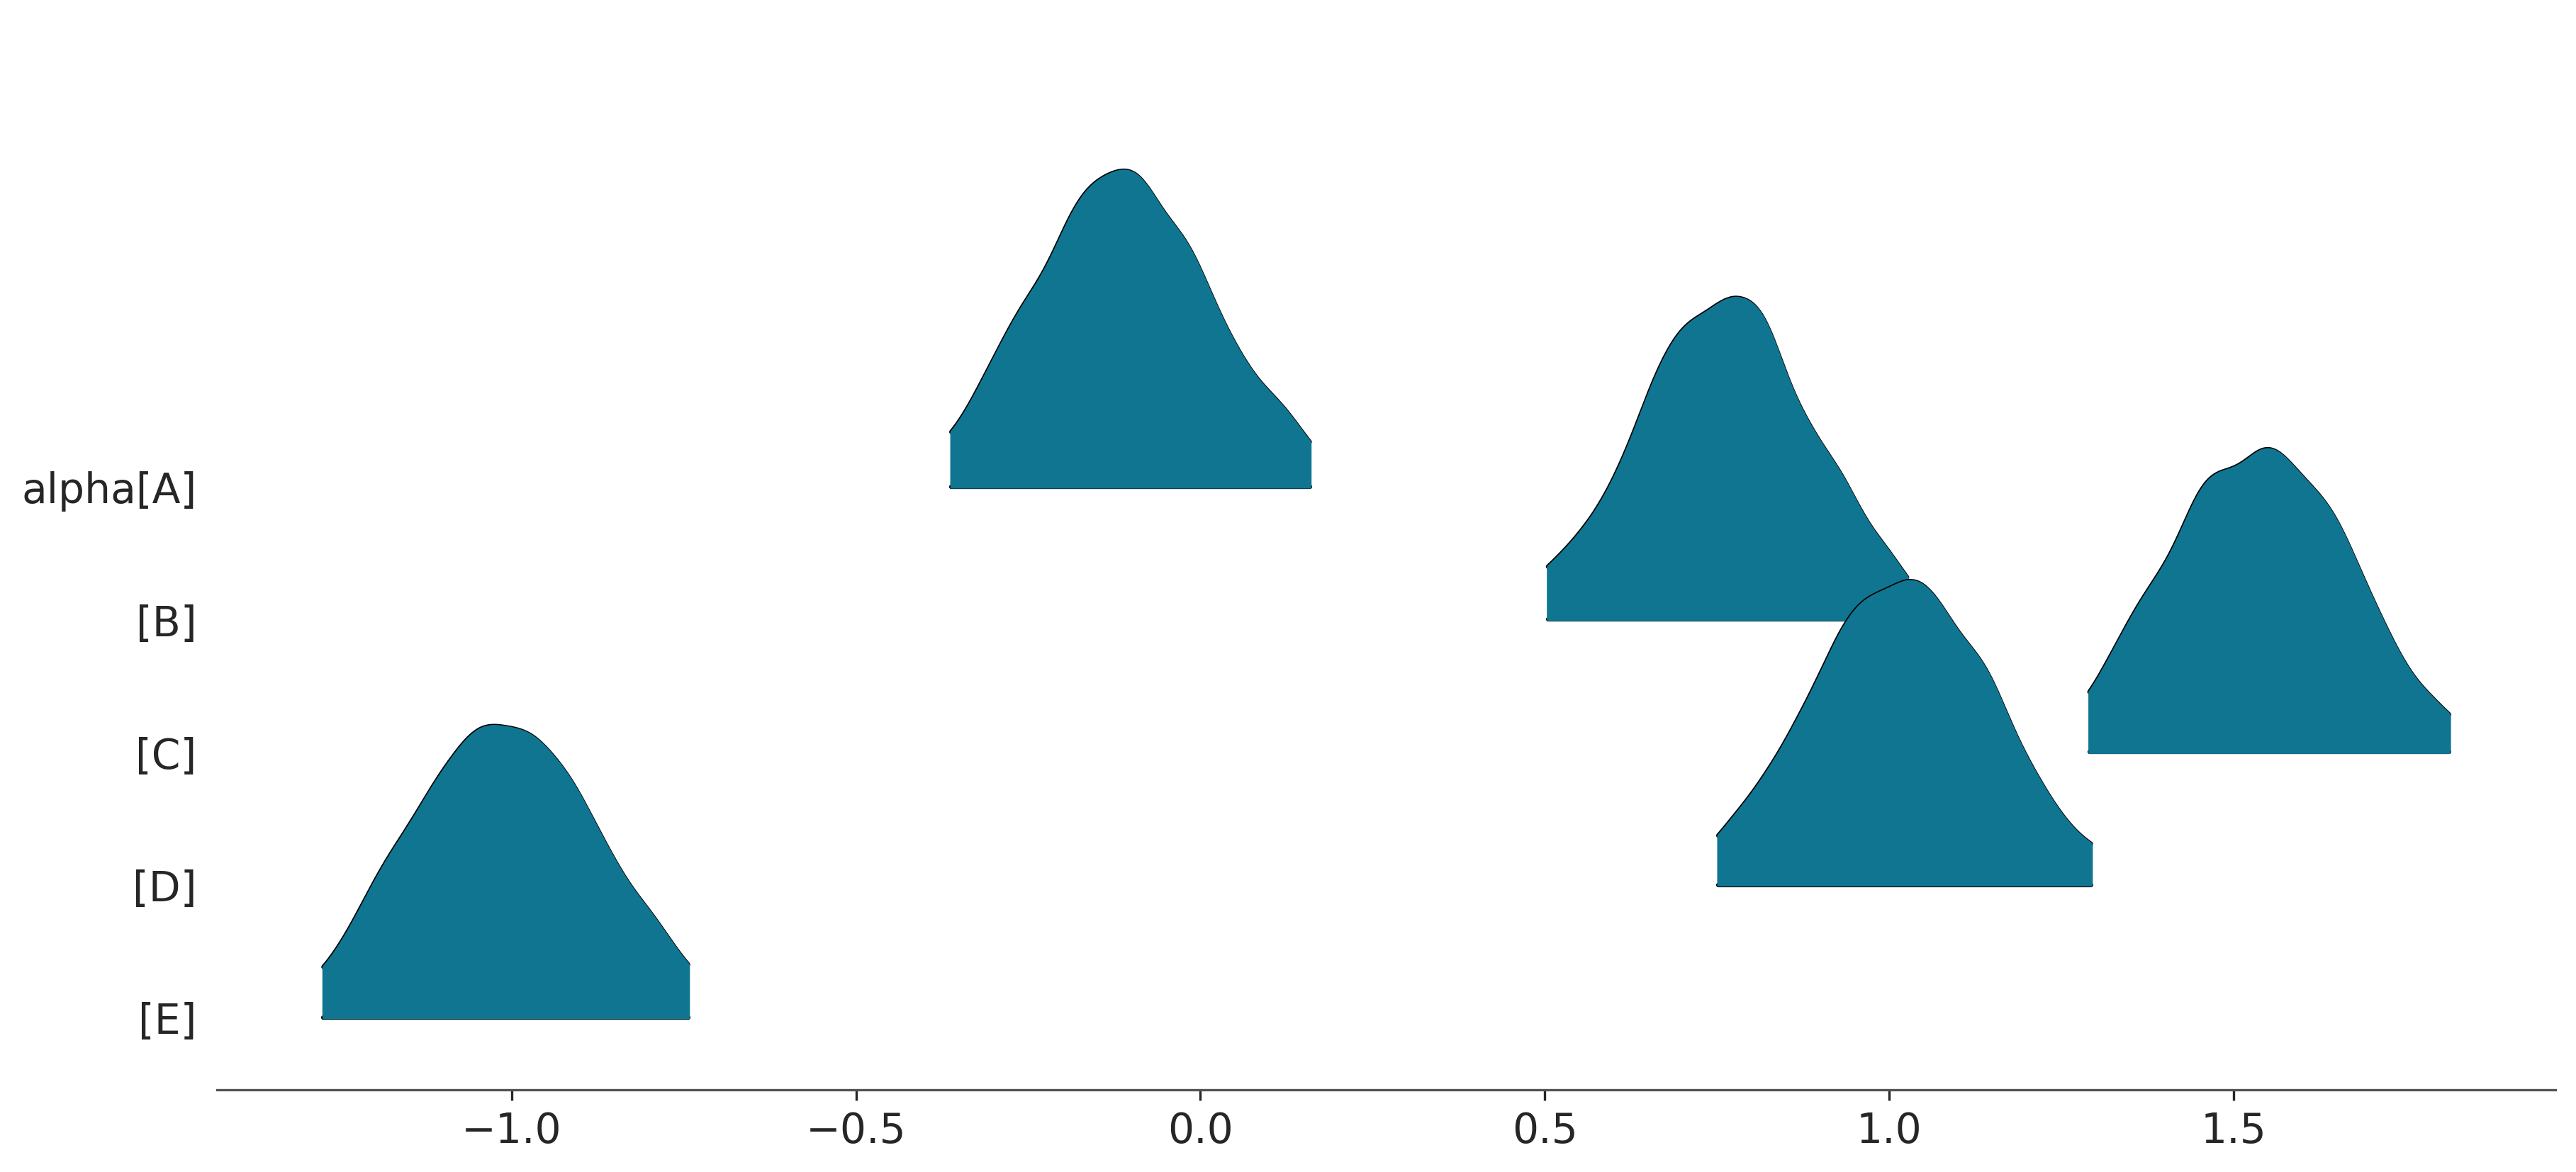

In [52]:
az.plot_forest(idata, combined=True, var_names=["alpha"], hdi_prob=0.95, kind="ridgeplot")

... yeah the above kind of looks ugly LOL ... 
to actually reproduce the `slabinterval` geom one would need to do something else ... 